# Example for using climate models

This notebook aims at using the climate model class of AeroMAPS, which relies on the use of the [AeroCM](https://github.com/AeroMAPS/AeroCM) framework.

## Import librairies and configuration

In [1]:
# --- Import libraries ---
%matplotlib widget
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# --- AeroMPAS processes ---
from aeromaps import create_process

## Set models

The choice of the models is directly managed through the use of configuration files provided in `./data`.

On the one hand, some basic models from AeroMAPS are used, in addition to the default energy carriers models. Note that two specific AeroMAPS models are also studied alternatively: the `FuelEffectCorrectionContrails` model which allows taking into account the effects of alternative fuels on contrails, and the `WithoutFuelEffectCorrectionContrails` one which does not allow them.

On the other hand, the climate models are considered using the `ClimateModel` class. Currently, 4 aviation climate models are available: IPCC, GWP*, LWE, FaIR. Default settings for the different climate models are available, but the user can change them easily by modifying the yaml climate model data file. 

## Create process and computation

This example notebook uses the default AeroMAPS inputs data.

We are creating 6 processes, corresponding to 6 configuration files:
- 4 processes correspond to the different climate models with default settings, coupled to the use of the `FuelEffectCorrectionContrails` model
- 1 process correspond to the FaIR climate model with default settings, coupled to the use of the `WithoutFuelEffectCorrectionContrails` model
- 1 process is a modified version of the FaIR climate model by assuming a lower climate sensitivity to contrails, coupled to the use of the `FuelEffectCorrectionContrails` model

In [3]:
process_fair_novpm = create_process(configuration_file="data/config_fair.yaml")
process_fair_novpm.parameters.karcher_curve_case = "No vPM"
process_fair_novpm.compute()

In [4]:
process_fair_intermediatevpm = create_process(configuration_file="data/config_fair.yaml")
process_fair_intermediatevpm.parameters.karcher_curve_case = "Intermediate vPM"
process_fair_intermediatevpm.compute()

In [5]:
process_fair_highvpm = create_process(configuration_file="data/config_fair.yaml")
process_fair_highvpm.parameters.karcher_curve_case = "High vPM"
process_fair_highvpm.compute()

In [6]:
process_fair_without_fuel_effect = create_process(configuration_file="data/config_fair_without_fuel_effect.yaml")
process_fair_without_fuel_effect.compute()

In [7]:
process_fair_without_fuel_effect_hydrogen_leakage = create_process(configuration_file="data/config_fair_without_fuel_effect.yaml")
process_fair_without_fuel_effect_hydrogen_leakage.parameters.h2_leakage_rate = 100.0
process_fair_without_fuel_effect_hydrogen_leakage.compute()

In [8]:
process_fair_without_fuel_effect_hydrogen_leakage.data["climate_outputs"][["h2_leakage"]]

,h2_leakage
1940,0
1941,0
1942,0
1943,0
1944,0
1945,0
1946,0
1947,0
1948,0
1949,0


In [9]:
process_fair_without_fuel_effect_hydrogen_leakage.data["climate_outputs"][["temperature_increase_from_h2_leakage_from_aviation"]]

,temperature_increase_from_h2_leakage_from_aviation
1940,0
1941,0
1942,0
1943,0
1944,0
1945,0
1946,0
1947,0
1948,0
1949,0


## Results

The user can then display the results for each configuration (e.g. default FaIR with the effects of alternative fuels on contrails).

We can for instance compare the results obtained for the different configurations.

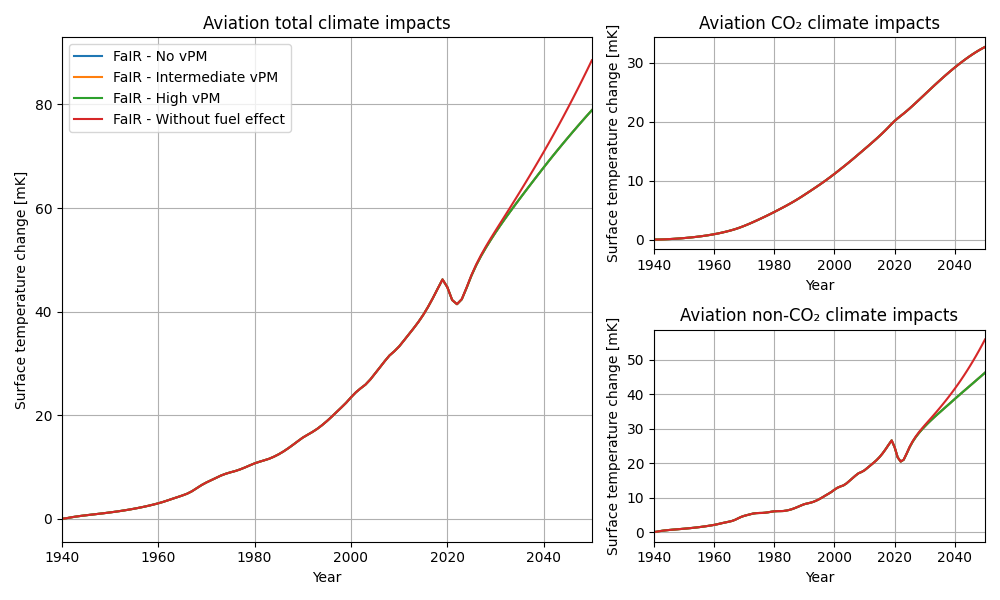

In [10]:
fig = plt.figure(figsize=(10, 6))
gs = gridspec.GridSpec(2, 2, width_ratios=[1.6, 1])
start_year = 1940
end_year = 2050
years_data = range(start_year, end_year+1)

ax1 = fig.add_subplot(gs[:, 0])
ax1.plot(years_data, 1000 * process_fair_novpm.data["climate_outputs"][["temperature_increase_from_aviation"]], label='FaIR - No vPM')
ax1.plot(years_data, 1000 * process_fair_intermediatevpm.data["climate_outputs"][["temperature_increase_from_aviation"]], label='FaIR - Intermediate vPM')
ax1.plot(years_data, 1000 * process_fair_highvpm.data["climate_outputs"][["temperature_increase_from_aviation"]], label='FaIR - High vPM')
ax1.plot(years_data, 1000 * process_fair_without_fuel_effect.data["climate_outputs"][["temperature_increase_from_aviation"]], label='FaIR - Without fuel effect')
ax1.legend()
ax1.grid()
ax1.set_xlim(start_year, end_year)
ax1.set_xlabel('Year')
ax1.set_ylabel('Surface temperature change [mK]')
ax1.set_title("Aviation total climate impacts")

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(years_data, 1000 * process_fair_novpm.data["climate_outputs"][["temperature_increase_from_co2_from_aviation"]], label='FaIR - No vPM')
ax2.plot(years_data, 1000 * process_fair_intermediatevpm.data["climate_outputs"][["temperature_increase_from_co2_from_aviation"]], label='FaIR - Intermediate vPM')
ax2.plot(years_data, 1000 * process_fair_highvpm.data["climate_outputs"][["temperature_increase_from_co2_from_aviation"]], label='FaIR - High vPM')
ax2.plot(years_data, 1000 * process_fair_without_fuel_effect.data["climate_outputs"][["temperature_increase_from_co2_from_aviation"]], label='FaIR - Without fuel effect')
ax2.grid()
ax2.set_xlim(start_year, end_year)
ax2.set_xlabel('Year')
ax2.set_ylabel('Surface temperature change [mK]')
ax2.set_title('Aviation CO₂ climate impacts')

ax3 = fig.add_subplot(gs[1, 1])
ax3.plot(years_data, 1000 * process_fair_novpm.data["climate_outputs"][["temperature_increase_from_non_co2_from_aviation"]], label='FaIR - No vPM')
ax3.plot(years_data, 1000 * process_fair_intermediatevpm.data["climate_outputs"][["temperature_increase_from_non_co2_from_aviation"]], label='FaIR - Intermediate vPM')
ax3.plot(years_data, 1000 * process_fair_highvpm.data["climate_outputs"][["temperature_increase_from_non_co2_from_aviation"]], label='FaIR - High vPM')
ax3.plot(years_data, 1000 * process_fair_without_fuel_effect.data["climate_outputs"][["temperature_increase_from_non_co2_from_aviation"]], label='FaIR - Without fuel effect')
ax3.grid()
ax3.set_xlim(start_year, end_year)
ax3.set_xlabel('Year')
ax3.set_ylabel('Surface temperature change [mK]')
ax3.set_title('Aviation non-CO₂ climate impacts')

plt.tight_layout()
plt.show()